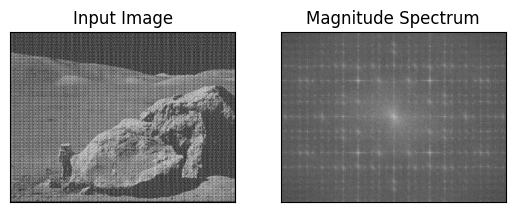

In [1]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt
 
img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)
if img is None:
    raise FileNotFoundError('Файл periodic_noise.jpg должен лежать рядом с ноутбуком')

dft = cv.dft(np.float32(img),flags = cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft, axes=(0, 1))
 
magnitude_spectrum = 20 * np.log(cv.magnitude(dft_shift[:, :, 0], dft_shift[:, :, 1]) + 1)
 
plt.subplot(121),plt.imshow(img, cmap = 'gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(magnitude_spectrum, cmap = 'gray')
plt.title('Magnitude Spectrum'), plt.xticks([]), plt.yticks([])
plt.show()

In [2]:
mask = np.zeros((img.shape[0],img.shape[1],2),np.uint8)
centerX, centerY = (int(img.shape[0] / 2),int(img.shape[1] / 2))
mask[centerX-50:centerX+50, centerY - 50:centerY+50,:] = 1

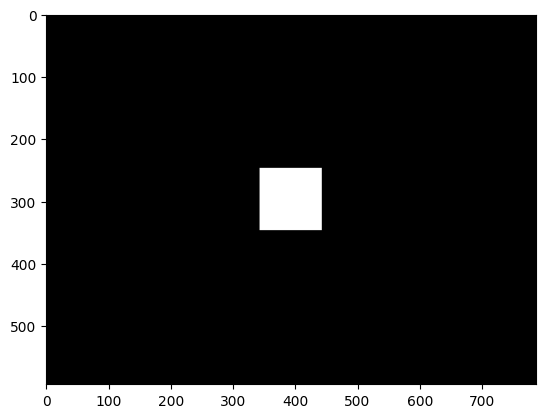

In [3]:
plt.imshow(mask[:,:,0], cmap = 'gray')

In [4]:
dft_shift = dft_shift*mask

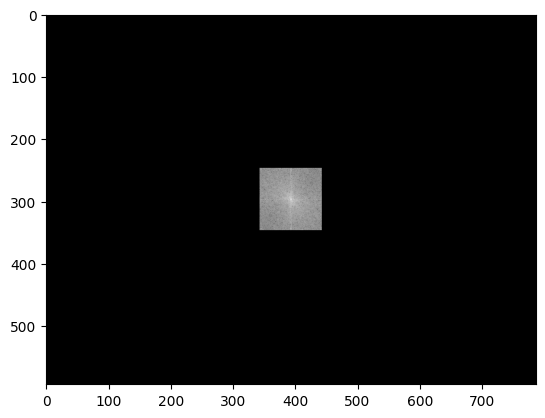

In [5]:
filtering_magn_res = 20 * np.log(cv.magnitude(dft_shift[:, :, 0], dft_shift[:, :, 1]) + 1)
plt.imshow(filtering_magn_res, cmap='gray')

In [6]:
f_ishift = np.fft.ifftshift(dft_shift, axes=(0, 1))
img_back = cv.idft(f_ishift, flags=cv.DFT_SCALE | cv.DFT_REAL_OUTPUT)

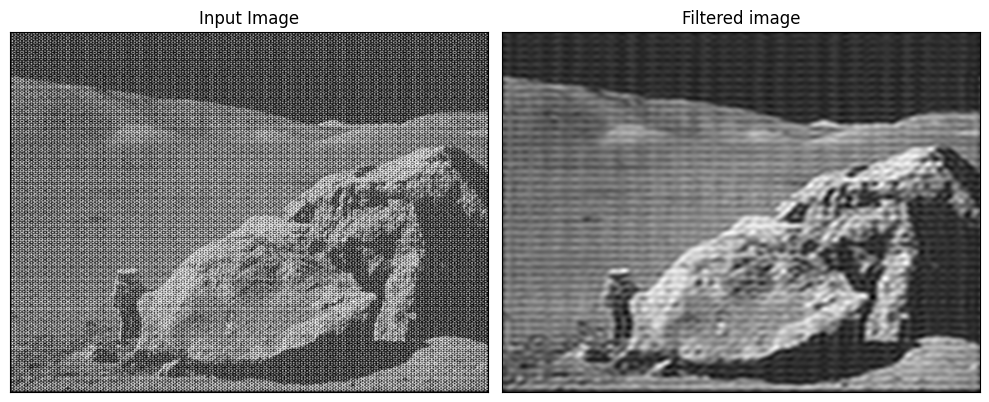

In [7]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Input Image')
plt.xticks([]), plt.yticks([])
plt.subplot(1, 2, 2)
plt.imshow(img_back, cmap='gray')
plt.title('Filtered image')
plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

# Task 1. Реализуйте высокочастотную фильтрацию на основе ядра Гаусса

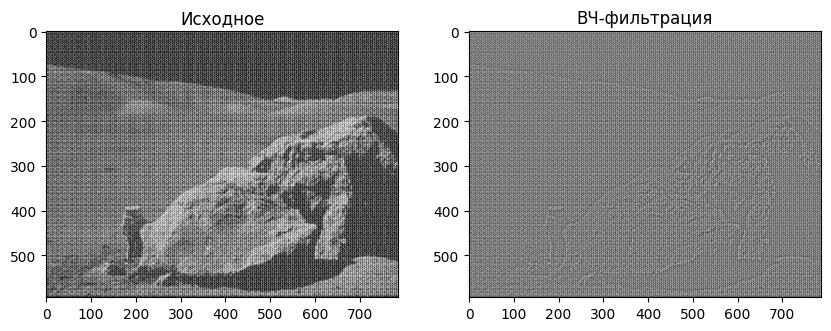

In [8]:
sigma = 3
blur = cv.GaussianBlur(img.astype(np.float32), (0, 0), sigma)
high_pass = img.astype(np.float32) - blur
high_pass = cv.normalize(high_pass, None, 0, 255, cv.NORM_MINMAX)

plt.figure(figsize=(10, 4))
plt.subplot(121), plt.imshow(img, cmap='gray'), plt.title('Исходное')
plt.subplot(122), plt.imshow(high_pass, cmap='gray'), plt.title('ВЧ-фильтрация')
plt.show()

# Task 2. Реализуйте вычисление свертки с помощью преобразования Фурье

Максимальная разница с cv.filter2D: 0.000102


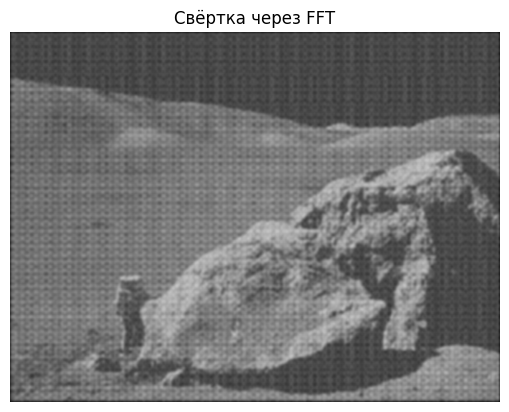

In [9]:
kernel = cv.getGaussianKernel(9, 2)
kernel = kernel @ kernel.T
h, w = img.shape
kh, kw = kernel.shape
shape = (h + kh - 1, w + kw - 1)

F_img = np.fft.fft2(img, shape)
F_kernel = np.fft.fft2(kernel, shape)
conv = np.fft.ifft2(F_img * F_kernel).real
conv = conv[kh//2:kh//2+h, kw//2:kw//2+w]

# Проверка: сравниваем FFT-свёртку с обычной (с нулевыми границами).
check = cv.filter2D(img.astype(np.float32), -1, kernel, borderType=cv.BORDER_CONSTANT)
error = np.max(np.abs(conv - check))
print(f'Максимальная разница с cv.filter2D: {error:.6f}')
assert np.allclose(conv, check, atol=1e-3)

plt.imshow(conv, cmap='gray', vmin=0, vmax=255)
plt.title('Свёртка через FFT')
plt.axis('off')
plt.show()

# Task 3. Реализуйте удаление периодического шума с помощью преобразования Фурье

Найдено пар частотных пиков: 100


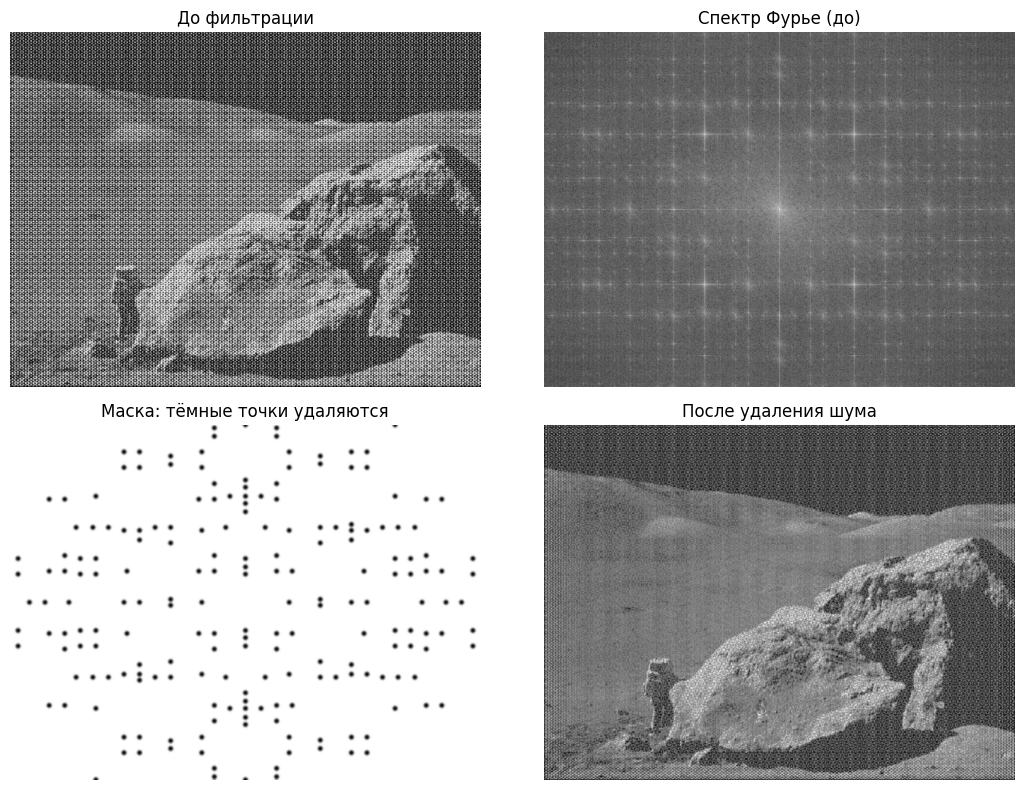

In [10]:
F = np.fft.fftshift(np.fft.fft2(img))
spectrum = np.log1p(np.abs(F))
h, w = img.shape
cy, cx = h // 2, w // 2
Y, X = np.ogrid[:h, :w]

# Находим яркие пики периодического шума в спектре.
score = spectrum - cv.GaussianBlur(spectrum, (0, 0), 3)
score[(Y-cy)**2 + (X-cx)**2 < 25**2] = 0
local_max = cv.dilate(score.astype(np.float32), np.ones((5, 5), np.uint8))
peaks = np.argwhere((score > 2.2) & (score >= local_max - 1e-4))
peaks = sorted(peaks, key=lambda p: score[tuple(p)], reverse=True)

mask = np.ones((h, w), np.float32)
chosen = []
for y, x in peaks:
    if y < cy or (y == cy and x < cx):
        continue
    if any(np.hypot(y-py, x-px) < 10 for py, px in chosen):
        continue
    chosen.append((y, x))
    for yy, xx in [(y, x), ((2*cy-y) % h, (2*cx-x) % w)]:
        cv.circle(mask, (int(xx), int(yy)), 4, 0, -1)
    if len(chosen) == 100:
        break

mask = cv.GaussianBlur(mask, (0, 0), 1.5)
result = np.fft.ifft2(np.fft.ifftshift(F * mask)).real

print(f'Найдено пар частотных пиков: {len(chosen)}')

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
plots = [
    (img, 'До фильтрации', 0, 255),
    (spectrum, 'Спектр Фурье (до)', None, None),
    (mask, 'Маска: тёмные точки удаляются', 0, 1),
    (np.clip(result, 0, 255), 'После удаления шума', 0, 255),
]
for ax, (data, title, vmin, vmax) in zip(axes.flat, plots):
    ax.imshow(data, cmap='gray', vmin=vmin, vmax=vmax)
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()